# VHR metadata dashboard for CSDA
| Author | Affiliation | Date |
| ---------------- | ---------------- | ---------------- |
| Paul Montesano, PhD | Innovation Lab ; NASA Goddard Space Flight Center | March 2026 |

In [1]:
# Load required libraries
library(sf)
library(dplyr)
library(ggplot2)
library(patchwork)
library(lubridate)
library(scales)
# library(rnaturalearth)
# library(rnaturalearthdata)
library(viridis)
library(ggspatial)

Linking to GEOS 3.12.2, GDAL 3.9.1, PROJ 9.4.1; sf_use_s2() is TRUE

Warning message:
“package ‘dplyr’ was built under R version 4.4.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”
Warning message:
“package ‘patchwork’ was built under R version 4.4.3”
Warning message:
“package ‘lubridate’ was built under R version 4.4.3”

Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Warning message:
“package ‘scales’ was built under R version 4.4.3”
Warning message:
“package ‘viridis’ was built under R version 4.4.3”
Loading required package: viridisLite

Warning message:
“package ‘viridisLite’ was built under R version 4.4.3”

Attaching package: ‘viridis’


The following object is masked from ‘package

## CONFIGURATION

In [2]:
source('/home/pmontesa/code/csda_summaries/lib/vhrmetalib.r')

## Standardize: CSDA STAC needs standardized columns

In [3]:
PLATFORM_LIST = c( 'planet','maxar-legion')
PLATFORM_LIST = c( 
    'planet'
   ,'satellogic'
   ,'maxar-legion'
)

In [4]:
# =============================================================================
# CONFIGURATION
# =============================================================================

gdf_list = list()
# =============================================================================
# READ DATA
# =============================================================================

for(PLATFORM in PLATFORM_LIST ){

    gpkg_path = paste0('stac_',PLATFORM,'.gpkg')
    
    cat("Reading geopackage...\n")
    stac_gdf <- st_read(gpkg_path, quiet = TRUE)
    
    cat(sprintf("Loaded %d stac records\n", nrow(stac_gdf)))
    cat(sprintf("Columns: %s\n", paste(names(stac_gdf), collapse=", ")))

    # Standardize STAC data
    stac_gdf_standardized <- standardize_stac_columns(stac_gdf, platform = PLATFORM)
    
    if(PLATFORM == 'planet'){
      stac_gdf_standardized <- stac_gdf_standardized %>% 
        mutate(`sensor/generation` = sensor_full_names[`sensor/generation`]) %>%
        mutate(`constellation` = case_when(
              grepl("RapidEye", sat_id, ignore.case = TRUE) ~ "RapidEye",
              grepl("SS", sat_id, ignore.case = TRUE) ~ "SkySat",
              grepl("PS", `sensor/generation`, ignore.case = TRUE) ~ "PlanetScope", 
              grepl(".SD", `sensor/generation`, ignore.case = TRUE) ~ "PlanetScope", 
              grepl('planet', `constellation`, ignore.case = FALSE) ~ "other",
              is.na(`constellation`) ~ affiliation,
              TRUE ~ `constellation`
            )) #%>%
        # mutate(`sensor/generation` = case_when(
        #   is.na(`sensor/generation`) ~ sat_id,
        #   TRUE ~ `sensor/generation`
        # ))
        
    }

    gdf_list[[gpkg_path]] = stac_gdf_standardized
    }

stac_gdf_standardized = do.call('rbind', gdf_list)

# Prep the df
stac_gdf_standardized <- get_angular_divergence_column(stac_gdf_standardized)
stac_gdf_standardized <- add_temporal_fields(stac_gdf_standardized, datetime_col = 'datetime')

# Calculate centroids for plotting
stac_gdf_standardized_centroids <- stac_gdf_standardized %>%
  st_transform(4326) %>%
  st_centroid()

Reading geopackage...
Loaded 261783 stac records
Columns: id, collection, datetime, bbox, eo.gsd, eo.bands, eo.azimuth, pl.updated, pl.provider, pl.strip_id, eo.off_nadir, pl.item_type, pl.published, eo.instrument, eo.cloud_cover, eo.sun_azimuth, pl.satellite_id, eo.sun_elevation, pl.clear_percent, pl.cloud_percent, pl.ground_control, pl.shadow_percent, pl.visible_percent, pl.anomalous_pixels, pl.pixel_resolution, pl.publishing_stage, pl.quality_category, pl.snow_ice_percent, pl.heavy_haze_percent, pl.light_haze_percent, pl.clear_confidence_percent, pl.visible_confidence_percent, eo.epsg, pl.rows, pl.columns, pl.origin_x, pl.origin_y, pl.ps4b_geometry, pl.grid_cell, pl.black_fill, pl.catalog_id, pl.usable_data, site_name, pl.camera_id, pl.ground_control_ratio, pl.data_type, pl.granule_id, pl.product_id, pl.datatake_id, pl.mgrs_grid_id, pl.abs_orbit_number, pl.rel_orbit_number, pl.s2_processor_version, pl.product_generation_time, geom


Warning message in standardize_stac_columns(stac_gdf, platform = PLATFORM):
“Column pl.providor not found in dataframe for constellation”


Reading geopackage...
Loaded 145 stac records
Columns: id, collection, datetime, bbox, gsd, created, license, platform, proj.epsg, providers, instruments, satl.sat_id, view.azimuth, constellation, csda.item_type, eo.cloud_cover, view.off_nadir, satl.outcome_id, view.sun_azimuth, satl.exposure_sec, satl.product_name, view.sun_elevation, satl.product_version, view.incidence_angle, satl.satellite_generation, site_name, geom
Reading geopackage...
Loaded 42 stac records
Columns: id, collection, datetime, bbox, gsd, platform, instrument, end_datetime, view.azimuth, csda.item_type, eo.cloud_cover, start_datetime, view.off_nadir, csda.band_count, processing.level, view.sun_azimuth, maxar_legion.mode, view.sun_elevation, maxar_legion.pniirs, maxar_legion.prod_cat_id, maxar_legion.product_type, maxar_legion.local_version, maxar_legion.scan_direction, maxar_legion.number_of_looks, maxar_legion.mean_intrack_angle, maxar_legion.mean_sat_elevation, maxar_legion.pansharpen_algorithm, maxar_legion.mea

Warning message:
“st_centroid assumes attributes are constant over geometries”


In [5]:
head(stac_gdf_standardized)

Registered S3 method overwritten by 'geojsonsf':
  method        from   
  print.geojson geojson



,id,collection,datetime,affiliation,sensor/generation,constellation,sat_id,el,az,sunel,sunaz,offnadir,gsd,geom,ang_div,date,year,month,doy
,<chr>,<chr>,<dttm>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<MULTIPOLYGON [°]>,<dbl>,<date>,<int>,<int>,<int>
stac_planet.gpkg.1,PSScene-20251005_181950_73_24dc,planet,2025-10-05,planet,SuperDove (PSB.SD),PlanetScope,24dc,86.3,277.2,49.1,165.8,3.7,3.6,MULTIPOLYGON (((-106.9955 3...,42.36550,2025-10-05,2025,10,278
stac_planet.gpkg.2,PSScene-20251005_181948_57_24dc,planet,2025-10-05,planet,SuperDove (PSB.SD),PlanetScope,24dc,86.3,277.2,48.9,165.9,3.7,3.6,MULTIPOLYGON (((-106.9598 3...,42.55886,2025-10-05,2025,10,278
stac_planet.gpkg.3,PSScene-20251005_181946_41_24dc,planet,2025-10-05,planet,SuperDove (PSB.SD),PlanetScope,24dc,86.3,277.2,48.8,166.0,3.7,3.6,MULTIPOLYGON (((-106.9238 3...,42.65262,2025-10-05,2025,10,278
stac_planet.gpkg.4,PSScene-20251005_181738_40_24fa,planet,2025-10-05,planet,SuperDove (PSB.SD),PlanetScope,24fa,85.0,277.8,48.9,165.3,5.0,3.6,MULTIPOLYGON (((-106.6617 3...,43.21659,2025-10-05,2025,10,278
stac_planet.gpkg.5,PSScene-20251005_181736_23_24fa,planet,2025-10-05,planet,SuperDove (PSB.SD),PlanetScope,24fa,85.0,277.8,48.8,165.4,5.0,3.6,MULTIPOLYGON (((-106.6249 3...,43.30816,2025-10-05,2025,10,278
stac_planet.gpkg.6,PSScene-20250930_181924_94_253b,planet,2025-09-30,planet,SuperDove (PSB.SD),PlanetScope,253b,88.9,106.9,50.9,165.2,1.1,3.8,MULTIPOLYGON (((-106.9212 3...,38.53153,2025-09-30,2025,9,273


In [6]:
list(colnames(stac_gdf_standardized))

[[1]]
 [1] "id"                "collection"        "datetime"         
 [4] "affiliation"       "sensor/generation" "constellation"    
 [7] "sat_id"            "el"                "az"               
[10] "sunel"             "sunaz"             "offnadir"         
[13] "gsd"               "geom"              "ang_div"          
[16] "date"              "year"              "month"            
[19] "doy"

In [7]:
unique(stac_gdf_standardized$collection)

[1] "planet"       "satellogic"   "maxar-legion"

In [8]:
unique(stac_gdf_standardized$affiliation)

[1] "planet"       "satellogic"   "maxar-legion"

In [9]:
unique(stac_gdf_standardized$`sensor/generation`)

[1] "SuperDove (PSB.SD)" "Dove (PS2)"         "SuperDove (PS2.SD)"
[4] NA                   "Sentinel-2"         "Dove-R (PS1)"      
[7] "Dove Classic (PS0)" "NewSat"             "WorldView Legion"

In [10]:
levels(factor(stac_gdf_standardized$`sensor/generation`))

[1] "Dove (PS2)"         "Dove Classic (PS0)" "Dove-R (PS1)"      
[4] "NewSat"             "Sentinel-2"         "SuperDove (PS2.SD)"
[7] "SuperDove (PSB.SD)" "WorldView Legion"

In [11]:
unique(stac_gdf_standardized$`constellation`)

[1] "PlanetScope"  "RapidEye"     "SkySat"       "planet"       "Aleph1"      
[6] "maxar-legion"

In [12]:
levels(factor(stac_gdf_standardized_centroids$sensor))

[1] "Dove (PS2)"         "Dove Classic (PS0)" "Dove-R (PS1)"      
[4] "NewSat"             "Sentinel-2"         "SuperDove (PS2.SD)"
[7] "SuperDove (PSB.SD)" "WorldView Legion"

In [1]:
#levels(factor(stac_gdf_standardized$sat_id))

## Issue
#### This shows us that we often dont have the satellite geometry info

In [14]:
library(purrr)

Warning message:
“package ‘purrr’ was built under R version 4.4.3”

Attaching package: ‘purrr’


The following object is masked from ‘package:scales’:

    discard




In [15]:
calculate_summary <- function(data, group_vars) {
  data %>%
    st_drop_geometry() %>%
    #mutate(`sensor/generation` = ifelse(is.na(`sensor/generation`), `constellation`, `sensor/generation`)) %>%
    group_by(across(all_of(group_vars))) %>%
    summarise(
      acquisition_count = n(),
      az_mean = mean(az, na.rm=TRUE),
      az_na = sum(is.na(az)),
      az_na_pct = round(sum(is.na(az)) / n() * 100, 1),
      el_na = sum(is.na(el)),
      el_na_pct = round(sum(is.na(el)) / n() * 100, 1),
      offnadir_na = sum(is.na(offnadir)),
      offnadir_na_pct = round(sum(is.na(offnadir)) / n() * 100, 1),
      ang_div_na = sum(is.na(ang_div)),
      ang_div_na_pct = round(sum(is.na(ang_div)) / n() * 100, 1),
      any_na = sum(is.na(az) | is.na(el) | is.na(offnadir)),
      pct_missing_metadata = round(sum(is.na(az) | is.na(el) | is.na(offnadir)) / n() * 100, 1),
# pct_missing_acq_geom = round(sum((is.na(az) | az == 0) | 
#                                   (is.na(el) | el == 0) | 
#                                   (is.na(offnadir) | offnadir == 0)) / n() * 100, 1),
      .groups = 'drop'
    ) %>%
    arrange(across(all_of(group_vars)), desc(acquisition_count))
}

summary_by_provider <- calculate_summary(stac_gdf_standardized, "constellation")
summary_detailed    <- calculate_summary(stac_gdf_standardized_centroids, c("constellation", "sensor/generation"))

summary_by_provider
summary_detailed

constellation,acquisition_count,az_mean,az_na,az_na_pct,el_na,el_na_pct,offnadir_na,offnadir_na_pct,ang_div_na,ang_div_na_pct,any_na,pct_missing_metadata
<chr>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>
Aleph1,145,152.9339,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
PlanetScope,255149,186.8658,85116,33.4,5542,2.2,5542,2.2,85142,33.4,85142,33.4
RapidEye,2383,NaN,2383,100.0,0,0.0,0,0.0,2383,100.0,2383,100.0
SkySat,4246,186.6237,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
maxar-legion,42,172.8381,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
planet,5,NaN,5,100.0,0,0.0,0,0.0,5,100.0,5,100.0


constellation,sensor/generation,acquisition_count,az_mean,az_na,az_na_pct,el_na,el_na_pct,offnadir_na,offnadir_na_pct,ang_div_na,ang_div_na_pct,any_na,pct_missing_metadata
<chr>,<chr>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>
Aleph1,NewSat,145,152.9339,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
PlanetScope,Dove (PS2),154808,181.7652,76629,49.5,5359,3.5,5359,3.5,76646,49.5,76646,49.5
PlanetScope,Dove Classic (PS0),71,155.6268,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
PlanetScope,Dove-R (PS1),58,197.9825,1,1.7,0,0.0,0,0.0,1,1.7,1,1.7
PlanetScope,SuperDove (PS2.SD),15790,196.2723,8348,52.9,166,1.1,166,1.1,8348,52.9,8348,52.9
PlanetScope,SuperDove (PSB.SD),84422,190.7853,138,0.2,17,0.0,17,0.0,147,0.2,147,0.2
RapidEye,NA,2383,NaN,2383,100.0,0,0.0,0,0.0,2383,100.0,2383,100.0
SkySat,NA,4246,186.6237,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0
maxar-legion,WorldView Legion,42,172.8381,0,0.0,0,0.0,0,0.0,0,0.0,0,0.0


#### View some subsets

In [16]:
COLS_LIST = c('id','collection','datetime','pl.provider' ,'pl.item_type', 'pl.published', 'eo.instrument', 'pl.satellite_id', 'sensor','gsd','az','el','offnadir','sunel','sunaz','ang_div')
COLS_LIST = c('id','collection','datetime','constellation', 'sat_id', 'sensor/generation','gsd','az','el','offnadir','sunel','sunaz','ang_div')

In [17]:
# head(stac_gdf_standardized %>% 
#      #filter(pl.provider == 'planetscope')) %>% 
#     select( all_of(COLS_LIST) )
#      )

In [18]:
#head(stac_gdf_standardized_centroids %>% filter(sensor == 'planetscope')) %>% select( all_of(COLS_LIST) ) # this single record should be ignored

In [19]:
# tail(stac_gdf_standardized %>% 
#     filter(`constellation` == 'SkySat') %>% 
#     select( all_of(COLS_LIST) )
#      )

In [20]:
#head(stac_gdf_standardized %>% filter(sensor == 'skysat')) %>% select( all_of(COLS_LIST) )

In [21]:
#levels(factor(stac_gdf_standardized_centroids$sensor))
# 'esa''planetscope''PlanetScope 0 (Dove Classic)''PlanetScope 1 (Dove-R)''PlanetScope 2 (Dove)''PlanetScope 2 SuperDove''PlanetScope SuperDove''rapideye''skysat'

In [22]:
source('/home/pmontesa/code/csda_summaries/lib/vhrmetalib.r')

## Not sure if acquisition geometry is correct for Planet

Warning message in geom_histogram(bins = 20, alpha = 0.7, color = "black", size = 0.2):
“Ignoring unknown parameters: `size`”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


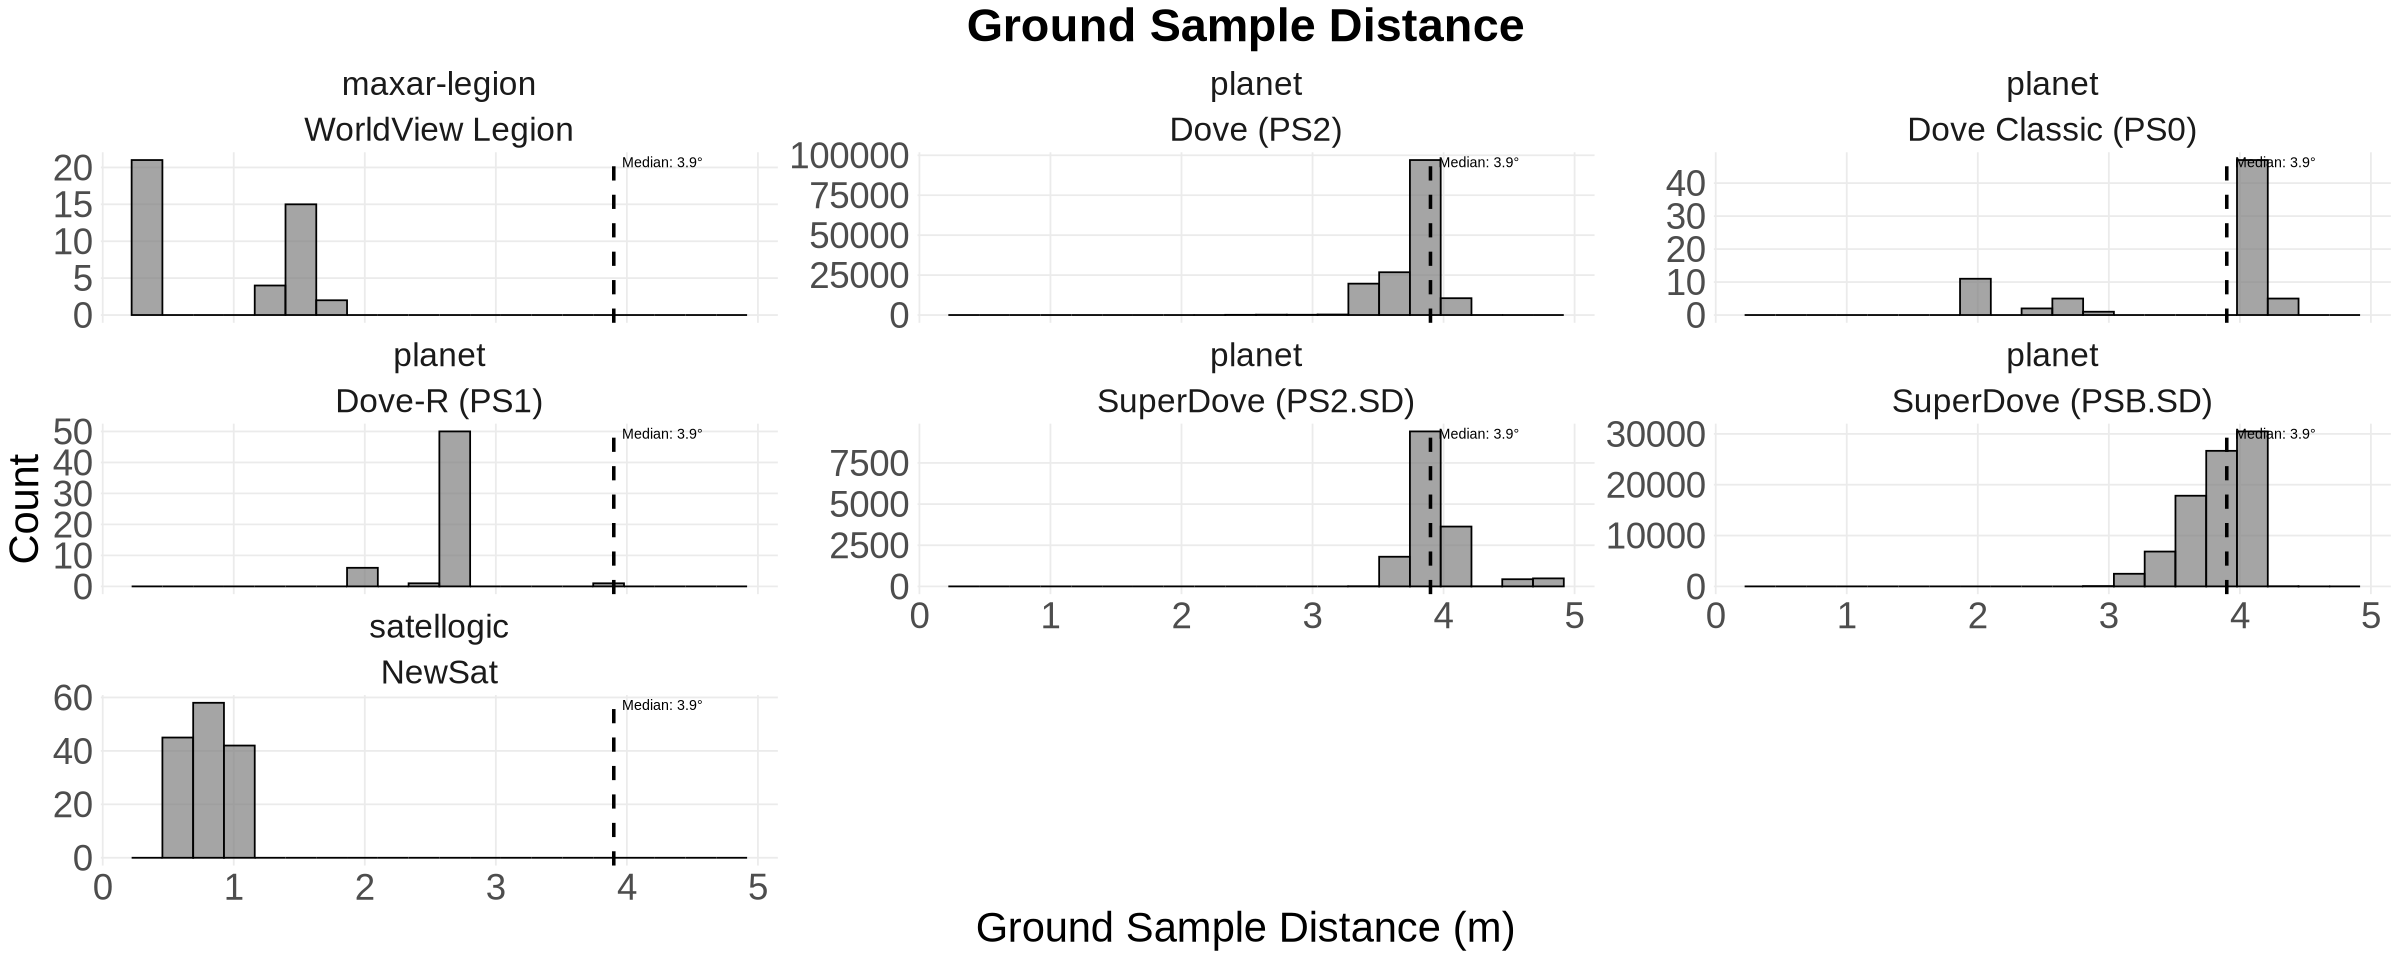

In [23]:
options(repr.plot.width = 20, repr.plot.height = 8)

create_gsd_histogram(stac_gdf_standardized %>% filter(`sensor/generation` != 'Sentinel-2'), fill_var = 'sensor/generation') + 
  theme(
    text = element_text(size = 25),           # All text
    plot.title = element_text(size = 28),     # Title specifically
    axis.text = element_text(size = 22),      # Axis labels
    legend.text = element_text(size = 12),    # Legend text
    strip.text = element_text(size = 20)      # Facet labels
  ) + facet_wrap(~ affiliation+`sensor/generation`, ncol=3, scales='free_y')

Warning message in geom_point(aes(x = 0, y = 0), inherit.aes = FALSE, shape = 3, :
“All aesthetics have length 1, but the data has 170194 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range
(`geom_text()`).”


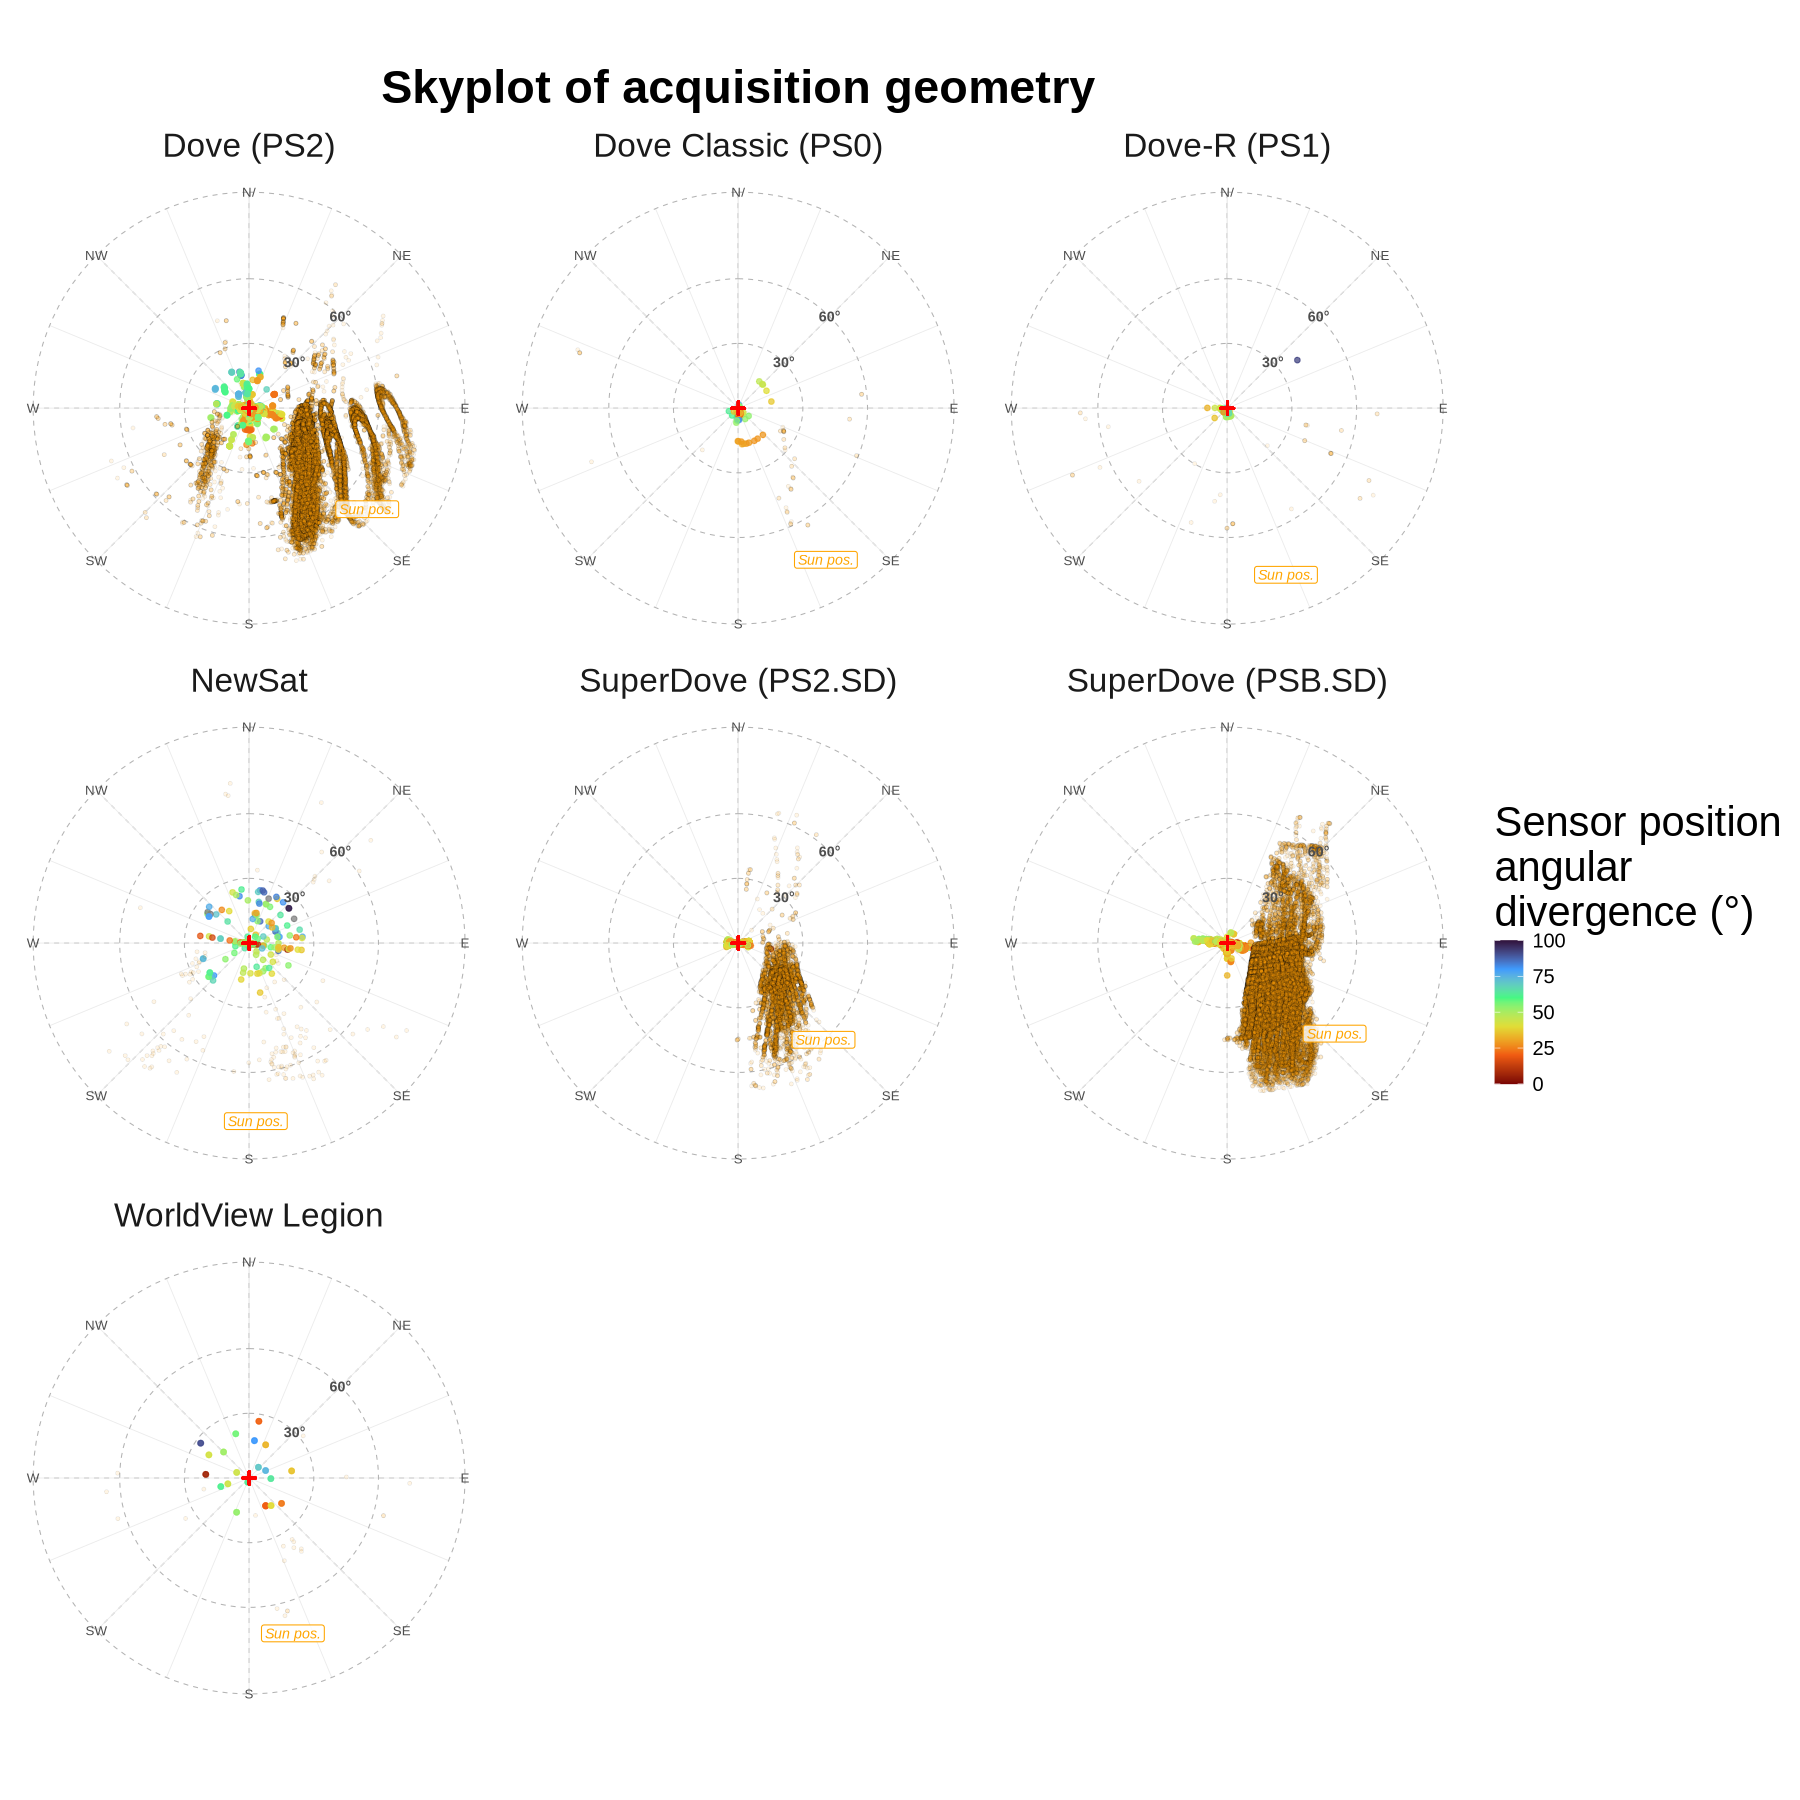

In [194]:
options(repr.plot.width = 15, repr.plot.height = 15)

create_polar_plot(stac_gdf_standardized_centroids, title = "Skyplot of acquisition geometry", 
                              color_palette = 'turbo', color_limits = c(0,100),
                              facet_by = "sensor/generation") + 
  theme(
    text = element_text(size = 25),           # All text
    plot.title = element_text(size = 28),     # Title specifically
    axis.text = element_text(size = 22),      # Axis labels
    legend.text = element_text(size = 12),    # Legend text
    strip.text = element_text(size = 20)      # Facet labels
  )

Warning message:
“st_centroid assumes attributes are constant over geometries”
Warning message:
“st_centroid assumes attributes are constant over geometries”


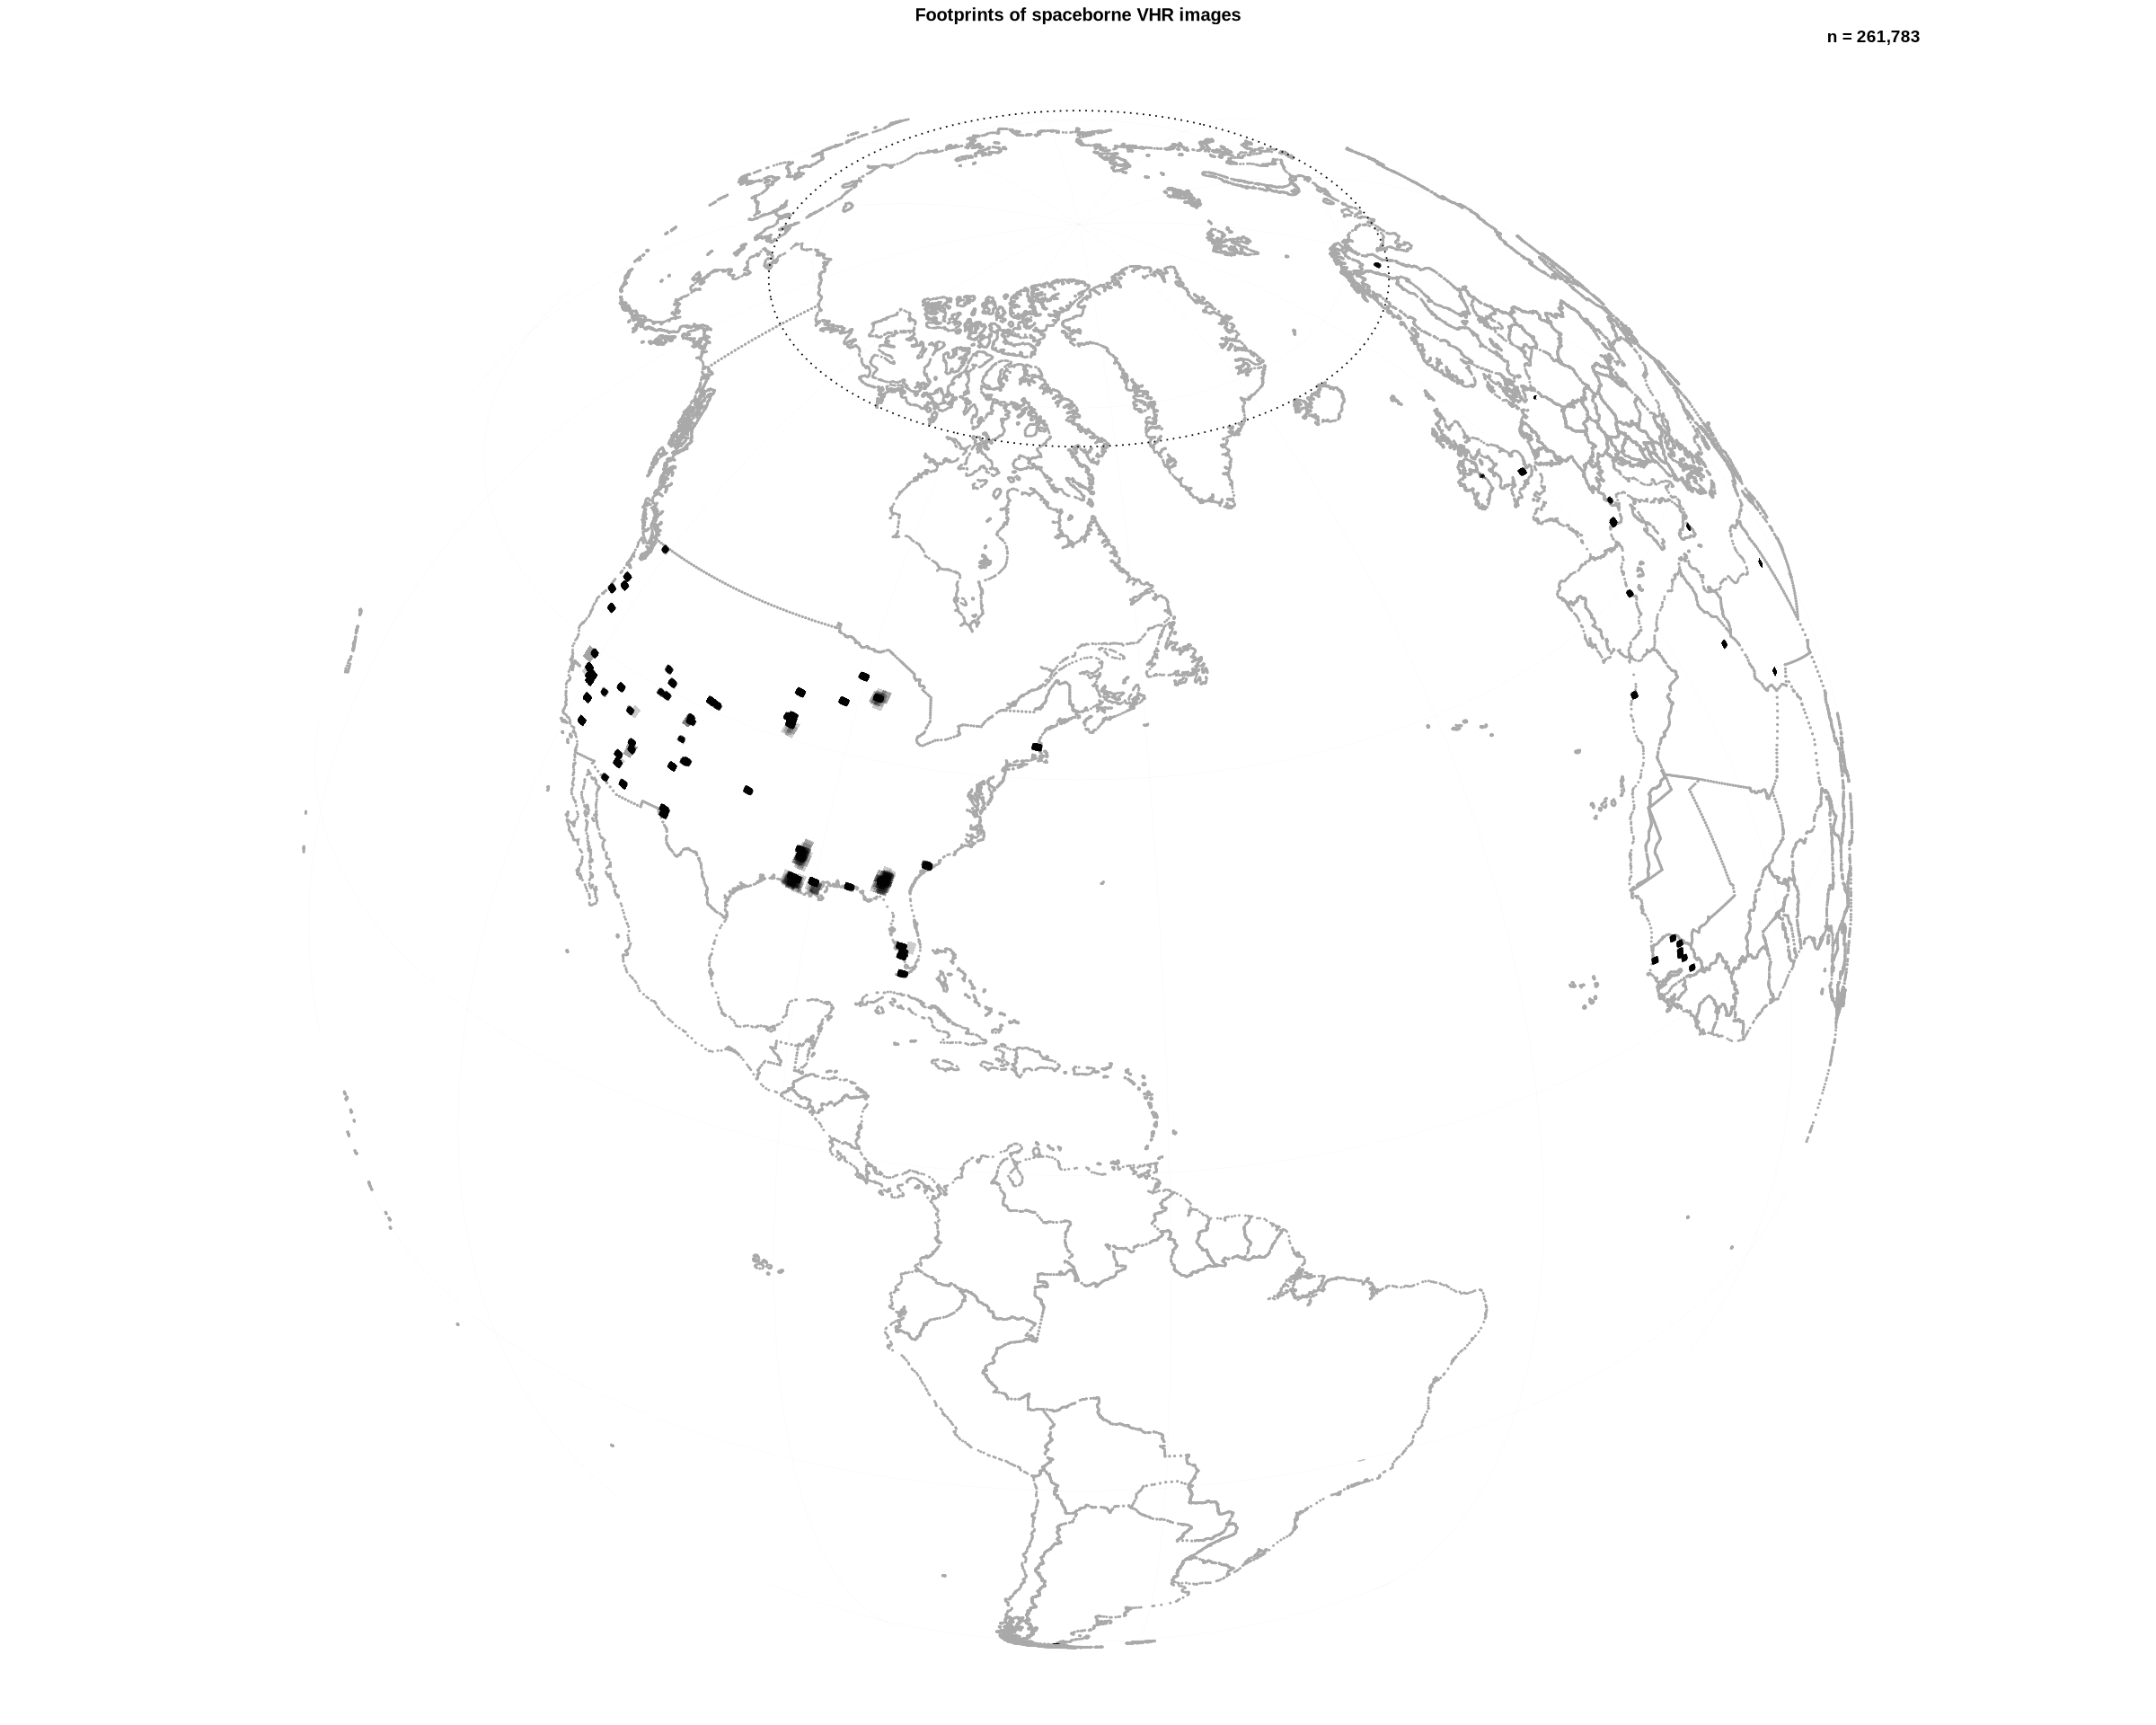

In [251]:
create_overview_map(stac_gdf_standardized, zoom=FALSE, , zoom_circle_scale = 3)

In [253]:
options(repr.plot.width = 20, repr.plot.height = 16)

dashboard_planet = create_dashboard_custom(stac_gdf_standardized, zoom=FALSE, facet_by='sensor')

print(dashboard_planet)

Creating dashboard plots...


Warning message:
“st_centroid assumes attributes are constant over geometries”
Warning message:
“st_centroid assumes attributes are constant over geometries”
Warning message in geom_histogram(aes(fill = after_stat(x)), bins = 30, color = "black", :
“Ignoring unknown parameters: `size`”
Warning message in geom_histogram(bins = 20, alpha = 0.7, color = "black", size = 0.2):
“Ignoring unknown parameters: `size`”
Warning message in geom_histogram(bins = 52, color = "black", size = 0.2):
“Ignoring unknown parameters: `size`”
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by sensor and year_.
ℹ Output is grouped by sensor.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(sensor, year_))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


ERROR: [1m[33mError[39m in `[[<-`:[22m
[1m[22m[33m![39m Assigned data `value` must be compatible with existing data.
[31m✖[39m Existing data has 41 rows.
[31m✖[39m Assigned data has 46 rows.
[36mℹ[39m Only vectors of size 1 are recycled.
[1mCaused by error in `vectbl_recycle_rhs_rows()`:[22m
[33m![39m Can't recycle input of size 46 to size 41.


## Run VHR dashboard plot - All TOAs

Creating dashboard plots...


Warning message:
“st_centroid assumes attributes are constant over geometries”
Warning message:
“st_centroid assumes attributes are constant over geometries”
`summarise()` has grouped output by 'sensor'. You can override using the
`.groups` argument.
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_text()`).”
Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_bar()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_text()`).”
Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_bar()`).”


Dashboard saved to: /projects/my-public-bucket/above_shrubs/paper_figs/vhr_acq_summary_dashboard_alaska_july_aug_n1651.png


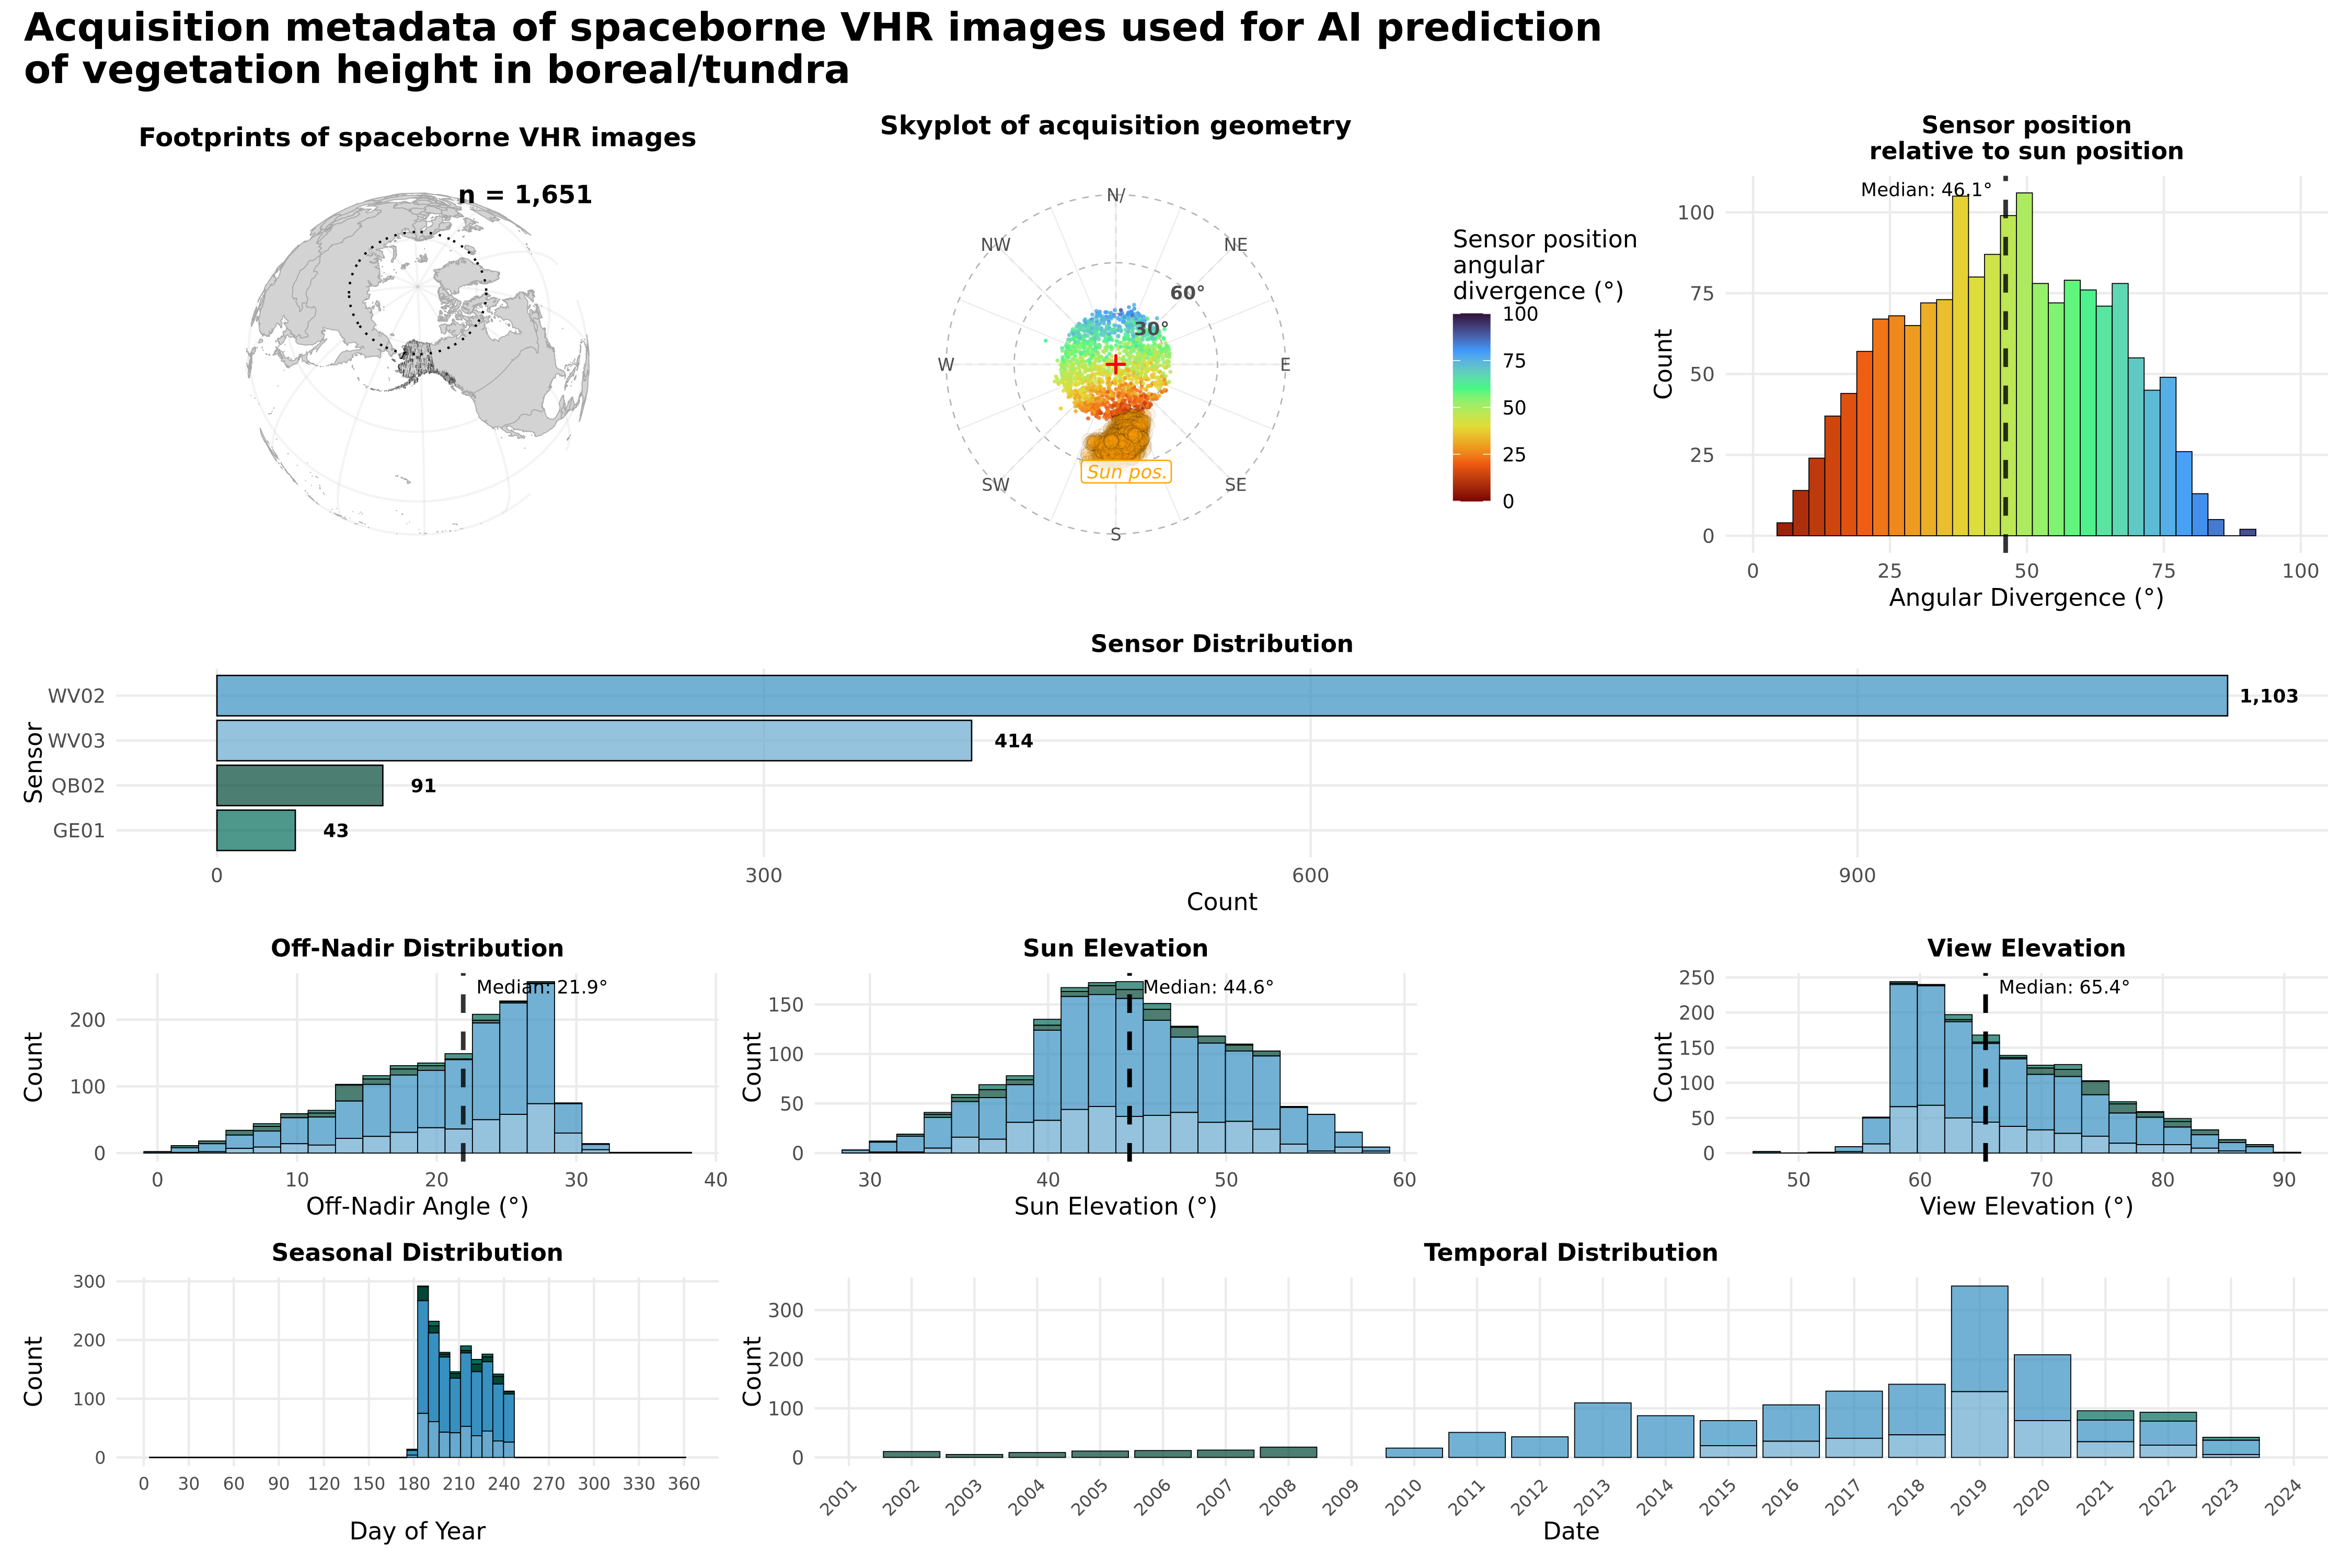

In [364]:
dashboard = create_dashboard_custom(footprints)

print(dashboard)

# Save
output_path <- paste0("/projects/my-public-bucket/above_shrubs/paper_figs/vhr_acq_summary_dashboard_alaska_july_aug_n",nrow(footprints),".png")
ggsave(
  output_path,
  plot = dashboard,
  width = 12,
  height = 8,
  dpi = 300,
  bg = "white"
)
cat(sprintf("Dashboard saved to: %s\n", output_path))